0.0
0.015811388300841896
0.022360679774997897
0.027386127875258306
0.03162277660168379
0.035355339059327376
0.03872983346207417
0.04183300132670378
0.044721359549995794
0.04743416490252569
0.05
0.05244044240850758
0.05477225575051661
0.057008771254956896
0.05916079783099616
0.06123724356957945
0.06324555320336758
0.0651920240520265
0.0670820393249937
0.06892024376045111
0.07071067811865475
0.07245688373094719
0.07416198487095663
0.07582875444051551
0.07745966692414834
0.07905694150420949
0.0806225774829855
0.08215838362577492
0.08366600265340755
0.08514693182963201
0.08660254037844387
0.08803408430829504
0.08944271909999159
0.09082951062292476
0.09219544457292887
0.09354143466934854
0.09486832980505137
0.09617692030835673
0.09746794344808964
0.09874208829065749
0.1
0.10124228365658294
0.10246950765959599
0.1036822067666386
0.10488088481701516
0.10606601717798213
0.10723805294763608
0.108397416943394
0.10954451150103323
0.11067971810589328
0.11180339887498948
0.11291589790636214
0.11401

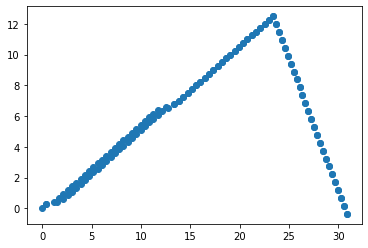

In [75]:
import numpy as np
import matplotlib.pyplot as plt
#First define the dimensions:
width=100
height=100

#And the grid distance:
delta_x=0.5
delta_y=0.5

#Now we define the refraction index:
#By default it will be all ones, but we can use a function

#The refraction index only depends on height, it's an array
n=np.ones((int(width/delta_x)))
#n=np.ones((int(width/delta_x),int(height/delta_y))) #w*h matrix full of 1

for i in range(int(len(n)/2)):
    print(np.sqrt(i/(20*len(n))))
    n[(len(n)-1-i)]+=-np.sqrt(5*(len(n)-i)/(100*len(n)))
#We put 2's in the las rows/colums:
#for i in range(int(len(n[:,0])/2)):
 #   for j in range(int(len(n[0,:]))):
  #      print(np.sqrt(i/(20*len(n[0,:]))))
   #     n[(len(n[:,0])-i-1),(len(n[0,:])-j-1)]+=-np.sqrt(i/(20*len(n[0,:])))
print(n)

#We choose the initial position and angle of the ray:
ray=[[0,0]]
angle=30*np.pi/180


#We select the velocity of the light:
c=1

#The dispe

#We just do iterations:
step_t=0.5 #constant, time passing between iterations
floor=0 #Number of times the ray touches the floor
current_index=0 #To see in which pixel we are
sum_h=0 #The sum of the height, to see if it passes to the next pixel


#We track te iterations number too:
i=0

#We need to know if the ray goes up (1) or down(-1)
direction=1 #At the beginning goes up

while (floor<2 and i<len(n)): #Needs to touch at the beginning and ending
    
    #We first see if it has touched the floor:
    if (ray[i][1]<=0):
        floor+=1
    #The n index depends on the height:
    n0=n[current_index]
    x=step_t*c/n0*np.cos(angle)
    y=step_t*c/n0*np.sin(angle)
    #We need to see if we have reached the next height with this last step
    #To do so, we check if the sum is bigger than the grid size:
    sum_h+=y
    if (sum_h>delta_y):
        current_index+=direction #We go to the next/previos grid
        n1=n[current_index]
        print(n1)
        #Snell law to calculate new angle.
        #CAUTION: Snell angle is taken from the normal and ours is from the horizontal axis:
        #We need to do sin(90-theta)=cos(theta)
        angle0=angle
        #CAREFUL: arcsin input has to be between -1 and 1. If it exceedes, add/substract 1
        if (((n0*np.cos(angle0))/n1)>1):
            #There has been an internal reflection, the wave can't pass:
            #The incident and refracted indexes are the same:
            angle=(3*np.pi/2)+angle0
            direction=-1 #It goes down now
        elif (((n0*np.cos(angle0))/n1)<-1):
            #No sé si se da esta opción
            angle=(np.pi/2.)-np.arcsin(((n0*np.cos(angle0))/n1)+1)
        else:
            angle=(np.pi/2.)-np.arcsin((n0*np.cos(angle0))/n1)
        #Now we need to calculate the height.
        #It divides into two heights:
        #1)height in previous cell: delta_y-sum_h
        #2)height in new cell with new angle and n:
        y1=(delta_y-sum_h)
        y2=(c/n1)*np.sin(angle)*(step_t-((delta_y-sum_h)/(c/n0)))
        y=y1+y2
        #The y can be negative, but the x is always positive (it moves forward)
        x=abs(y1/np.tan(angle0))+abs(y2/np.tan(angle))
        #We put the sum back to current height in next cell, to count again:
        sum_h=y2 
        #We add the new total position of our ray:
        ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
        
    else:
        #If it doesn't jump to next cell the ray will travel normally:
        ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
    
    #Next iteration:
    i+=1
print(i)
print(floor)
print(ray[-1])
for j in range(len(ray)-2):
    x=[ray[j][0],ray[j+2][0]]
    y=[ray[j][1],ray[j+2][1]]
    #plt.plot(x,y)
plt.figure(1)
x_axis=[]
y_axis=[]
for j in range(len(ray)):
    x_axis.append(ray[j][0])
    y_axis.append(ray[j][1])
print(y_axis)
plt.scatter(x_axis,y_axis)